# LeNet-5 (LeCun, Bottou, Bengio & Haffner, 1998)
*Gradient-Based Learning Applied to Document Recognition*, Proc. IEEE 86(11):2278–2324. doi:10.1109/5.726791

Faithful reimplementation on **MNIST** (60,000 train / 10,000 test, 28×28 padded to 32×32).

| Layer | Output | Params |
|---|---|---|
| C1 conv 5×5 | 6@28×28 | 156 |
| S2 trainable subsampling | 6@14×14 | 12 |
| C3 conv 5×5, sparse (Table I) | 16@10×10 | 1,516 |
| S4 trainable subsampling | 16@5×5 | 32 |
| C5 conv 5×5 | 120@1×1 | 48,120 |
| F6 full | 84 | 10,164 |
| Output Euclidean RBF (fixed) | 10 | 0 |
| **Total** | | **60,000** |

**Deviations:** the 7×12 RBF bitmaps are rendered from a font (the paper shows them only as a figure); plain SGD replaces stochastic diagonal Levenberg–Marquardt.

## 1. Imports and setup

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 2. Configuration
Paper: 20 passes, one sample per update. Use `BATCH = 64` for a much faster (less faithful) run.

In [2]:
EPOCHS = 20      # paper: 20 passes
LR     = 0.001   # base learning rate for plain SGD
BATCH  = 1       # paper: per-sample (stochastic) updates
J      = 0.1     # constant j in the MAP loss, Eq. (9)
DATA   = "./data"

## 3. Data — MNIST
Pixel values mapped so background = −0.1 and foreground = 1.175 (mean ≈ 0, variance ≈ 1), then padded 28×28 → 32×32 with background value.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),                                         # [0, 1]
    transforms.Lambda(lambda t: t * 1.275 - 0.1),                  # [-0.1, 1.175]
    transforms.Lambda(lambda t: F.pad(t, (2, 2, 2, 2), value=-0.1)),  # 32x32
])

train_set = datasets.MNIST(DATA, train=True,  download=True, transform=transform)
test_set  = datasets.MNIST(DATA, train=False, download=True, transform=transform)

train_loader      = DataLoader(train_set, batch_size=BATCH, shuffle=True)
train_eval_loader = DataLoader(train_set, batch_size=1000, shuffle=False)
test_loader       = DataLoader(test_set,  batch_size=1000, shuffle=False)

print(f"train: {len(train_set)}  test: {len(test_set)}  image: {tuple(train_set[0][0].shape)}")

100%|██████████| 9.91M/9.91M [00:05<00:00, 1.96MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 100kB/s]
100%|██████████| 1.65M/1.65M [00:02<00:00, 712kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.24MB/s]

train: 60000  test: 10000  image: (1, 32, 32)


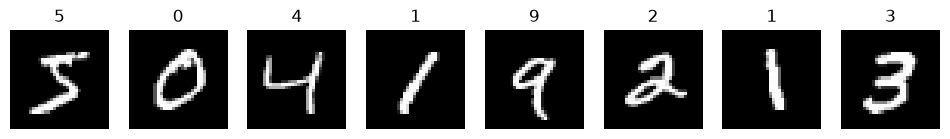

In [4]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, range(8)):
    img, lbl = train_set[i]
    ax.imshow(img[0], cmap="gray"); ax.set_title(lbl); ax.axis("off")
plt.show()

## 4. Squashing function, initialisation and the C3 connection table
$f(a) = 1.7159\,\tanh(\tfrac{2}{3}a)$; weights uniform in $[-2.4/F_{in},\,2.4/F_{in}]$ (Appendix A).

In [5]:
A, S = 1.7159, 2.0 / 3.0

def squash(x):
    return A * torch.tanh(S * x)

def uniform_init(shape, fan_in):
    return nn.Parameter((torch.rand(*shape) * 2 - 1) * 2.4 / fan_in)

# Table I: S2 maps feeding each of the 16 C3 maps
C3_TABLE = [
    [0, 1, 2], [1, 2, 3], [2, 3, 4], [3, 4, 5], [4, 5, 0], [5, 0, 1],
    [0, 1, 2, 3], [1, 2, 3, 4], [2, 3, 4, 5], [3, 4, 5, 0], [4, 5, 0, 1], [5, 0, 1, 2],
    [0, 1, 3, 4], [1, 2, 4, 5], [0, 2, 3, 5],
    [0, 1, 2, 3, 4, 5],
]

## 5. Subsampling layers (S2, S4) and sparse C3
Subsampling = sum of a 2×2 field × trainable coefficient + trainable bias, then squash (not max-pooling).

In [6]:
class Subsample(nn.Module):
    def __init__(self, maps):
        super().__init__()
        self.coef = nn.Parameter(torch.full((maps,), 0.25))   # starts as a 2x2 average
        self.bias = nn.Parameter(torch.zeros(maps))

    def forward(self, x):
        s = F.avg_pool2d(x, 2) * 4.0                          # 2x2 sum
        return squash(s * self.coef.view(1, -1, 1, 1) + self.bias.view(1, -1, 1, 1))


class C3(nn.Module):
    def __init__(self):
        super().__init__()
        self.w = nn.ParameterList(
            [uniform_init((1, len(src), 5, 5), 25 * len(src)) for src in C3_TABLE])
        self.b = nn.Parameter(torch.zeros(16))
        for j, src in enumerate(C3_TABLE):
            self.register_buffer(f"src{j}", torch.tensor(src))

    def forward(self, x):
        outs = [F.conv2d(x[:, getattr(self, f"src{j}")], self.w[j]) for j in range(16)]
        return torch.cat(outs, 1) + self.b.view(1, -1, 1, 1)

## 6. Fixed RBF centres (7×12 digit bitmaps, ±1)

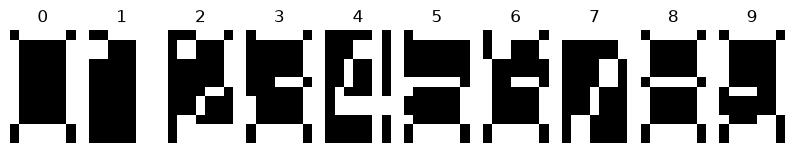

In [7]:
def rbf_bitmaps():
    from PIL import Image, ImageDraw, ImageFont
    font = ImageFont.load_default()
    codes = []
    for d in range(10):
        img = Image.new("L", (28, 48), 0)
        ImageDraw.Draw(img).text((8, 14), str(d), fill=255, font=font)
        ys, xs = np.nonzero(np.array(img))
        crop = img.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))
        bm = np.array(crop.resize((7, 12), Image.NEAREST)) > 127
        codes.append(np.where(bm, 1.0, -1.0).reshape(-1))
    return torch.tensor(np.stack(codes), dtype=torch.float32)

RBF = rbf_bitmaps()
fig, axes = plt.subplots(1, 10, figsize=(10, 2))
for d, ax in enumerate(axes):
    ax.imshow(RBF[d].view(12, 7), cmap="gray"); ax.set_title(d); ax.axis("off")
plt.show()

## 7. LeNet-5 model

In [8]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.C1w = uniform_init((6, 1, 5, 5), 25)
        self.C1b = nn.Parameter(torch.zeros(6))
        self.S2  = Subsample(6)
        self.C3  = C3()
        self.S4  = Subsample(16)
        self.C5w = uniform_init((120, 16, 5, 5), 16 * 25)
        self.C5b = nn.Parameter(torch.zeros(120))
        self.F6  = nn.Linear(120, 84)
        with torch.no_grad():
            self.F6.weight.copy_(uniform_init((84, 120), 120))
            self.F6.bias.zero_()
        self.register_buffer("rbf", RBF.clone())          # fixed, not trained

    def forward(self, x):
        x = squash(F.conv2d(x, self.C1w, self.C1b))        # 6x28x28
        x = self.S2(x)                                     # 6x14x14
        x = squash(self.C3(x))                             # 16x10x10
        x = self.S4(x)                                     # 16x5x5
        x = squash(F.conv2d(x, self.C5w, self.C5b))        # 120x1x1
        x = squash(self.F6(x.flatten(1)))                  # 84
        # RBF penalties: squared Euclidean distance to each class bitmap
        return ((x.unsqueeze(1) - self.rbf.unsqueeze(0)) ** 2).sum(-1)   # N x 10


model = LeNet5().to(device)
layers = {"C1": ["C1w", "C1b"], "S2": ["S2."], "C3": ["C3."], "S4": ["S4."],
          "C5": ["C5w", "C5b"], "F6": ["F6."]}
for name, prefixes in layers.items():
    n = sum(p.numel() for k, p in model.named_parameters() if any(k.startswith(q) for q in prefixes))
    print(f"{name}: {n:>6,}")
print(f"total: {sum(p.numel() for p in model.parameters()):,}  (paper: 60,000)")

C1:    156
S2:     12
C3:  1,516
S4:     32
C5: 48,120
F6: 10,164
total: 60,000  (paper: 60,000)


## 8. MAP loss — Eq. (9)
$E = y_{D} + \log\big(e^{-j} + \sum_i e^{-y_i}\big)$, where $y_i$ are RBF penalties and $D$ is the correct class.

In [9]:
def map_loss(y, target, j=J):
    y_d = y.gather(1, target.view(-1, 1)).squeeze(1)
    lse = torch.logsumexp(torch.cat([torch.full_like(y[:, :1], -j), -y], 1), 1)
    return (y_d + lse).mean()

## 9. Learning-rate schedule and evaluation
Paper schedule shape: 2 passes at η, 3 at 0.4η, 3 at 0.2η, 4 at 0.1η, then 0.02η. Prediction = class with the **smallest** penalty.

In [10]:
def lr_at(epoch, base=LR):
    rel = [1.0] * 2 + [0.4] * 3 + [0.2] * 3 + [0.1] * 4
    return base * (rel[epoch] if epoch < len(rel) else 0.02)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    err, n, loss = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss += map_loss(out, y).item() * y.size(0)
        err  += (out.argmin(1) != y).sum().item()
        n    += y.size(0)
    return loss / n, 100.0 * err / n

## 10. Training

In [11]:
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
history = {"train_err": [], "test_err": [], "train_loss": [], "test_loss": []}

for epoch in range(EPOCHS):
    for g in optimizer.param_groups:
        g["lr"] = lr_at(epoch)
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = map_loss(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    tr_loss, tr_err = evaluate(model, train_eval_loader)
    te_loss, te_err = evaluate(model, test_loader)
    for k, v in zip(history, (tr_err, te_err, tr_loss, te_loss)):
        history[k].append(v)
    print(f"pass {epoch + 1:2d} | lr {lr_at(epoch):.5f} | train err {tr_err:5.2f}% "
          f"| test err {te_err:5.2f}% | test loss {te_loss:.4f}")

pass  1 | lr 0.00100 | train err  2.50% | test err  2.65% | test loss 3.1830
pass  2 | lr 0.00100 | train err  2.06% | test err  2.22% | test loss 2.9158
pass  3 | lr 0.00040 | train err  1.26% | test err  1.59% | test loss 2.0258
pass  4 | lr 0.00040 | train err  1.15% | test err  1.45% | test loss 2.0119
pass  5 | lr 0.00040 | train err  0.96% | test err  1.43% | test loss 1.8834
pass  6 | lr 0.00020 | train err  0.78% | test err  1.40% | test loss 1.7548
pass  7 | lr 0.00020 | train err  0.72% | test err  1.28% | test loss 1.7347
pass  8 | lr 0.00020 | train err  0.69% | test err  1.26% | test loss 1.7337
pass  9 | lr 0.00010 | train err  0.60% | test err  1.27% | test loss 1.6907
pass 10 | lr 0.00010 | train err  0.60% | test err  1.26% | test loss 1.7071
pass 11 | lr 0.00010 | train err  0.56% | test err  1.24% | test loss 1.7060
pass 12 | lr 0.00010 | train err  0.54% | test err  1.22% | test loss 1.6852
pass 13 | lr 0.00002 | train err  0.53% | test err  1.26% | test loss 1.6733

## 11. Error curves (cf. Fig. 5 of the paper)

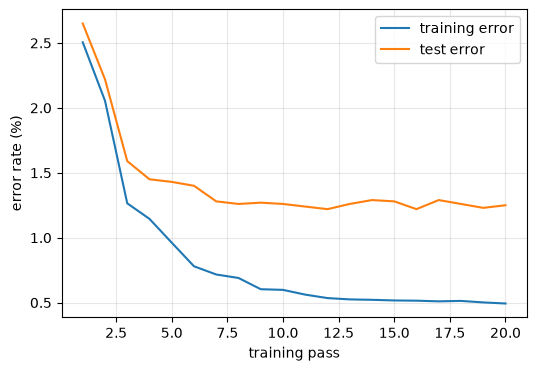

In [12]:
passes = range(1, len(history["test_err"]) + 1)
plt.figure(figsize=(6, 4))
plt.plot(passes, history["train_err"], label="training error")
plt.plot(passes, history["test_err"],  label="test error")
plt.xlabel("training pass"); plt.ylabel("error rate (%)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 12. Final result and checkpoint
Paper: **0.95 %** test error without distortions, **0.8 %** with distortions.

In [13]:
te_loss, te_err = evaluate(model, test_loader)
print(f"final test error: {te_err:.2f}%  (paper: 0.95%)")
torch.save(model.state_dict(), "lenet5_1998.pt")

final test error: 1.25%  (paper: 0.95%)
